In [ ]:
# Dependencias: instala PuLP 3 con el solver CBC, Matplotlib y NetworkX en el kernel del notebook.
%pip install --quiet "pulp>=3,<4" matplotlib networkx

ESTADO DE LA OPTIMIZACIÓN : Optimal
FLUJO MÁXIMO ÓPTIMO (F*)  : 20.0 cambios concurrentes/semana
CAPACIDAD CORTE MÍNIMO    : 20.0
ASIGNACIÓN DETALLADA DE FLUJO EN CADA INTERFAZ:
  Interfaz  s -> M1 : 11.0 / 12
  Interfaz  s -> M3 :  9.0 / 10
  Interfaz M1 -> M2 :  3.0 /  3 [SATURADO - CUELLO DE BOTELLA]
  Interfaz M1 -> t  :  8.0 /  8 [SATURADO - CUELLO DE BOTELLA]
  Interfaz M2 -> t  :  3.0 /  4
  Interfaz M2 -> M3 :  0.0 /  5
  Interfaz M3 -> t  :  9.0 /  9 [SATURADO - CUELLO DE BOTELLA]

PARTICIÓN ÓPTIMA DEL CORTE (DESACOPLAMIENTO ESTRATÉGICO):
  Lado Fuente   (S) : ['M1', 'M3', 's']
  Lado Sumidero (T) : ['M2', 't']
  Interfaces críticas a refactorizar : [('M1', 't'), ('M1', 'M2'), ('M3', 't')]


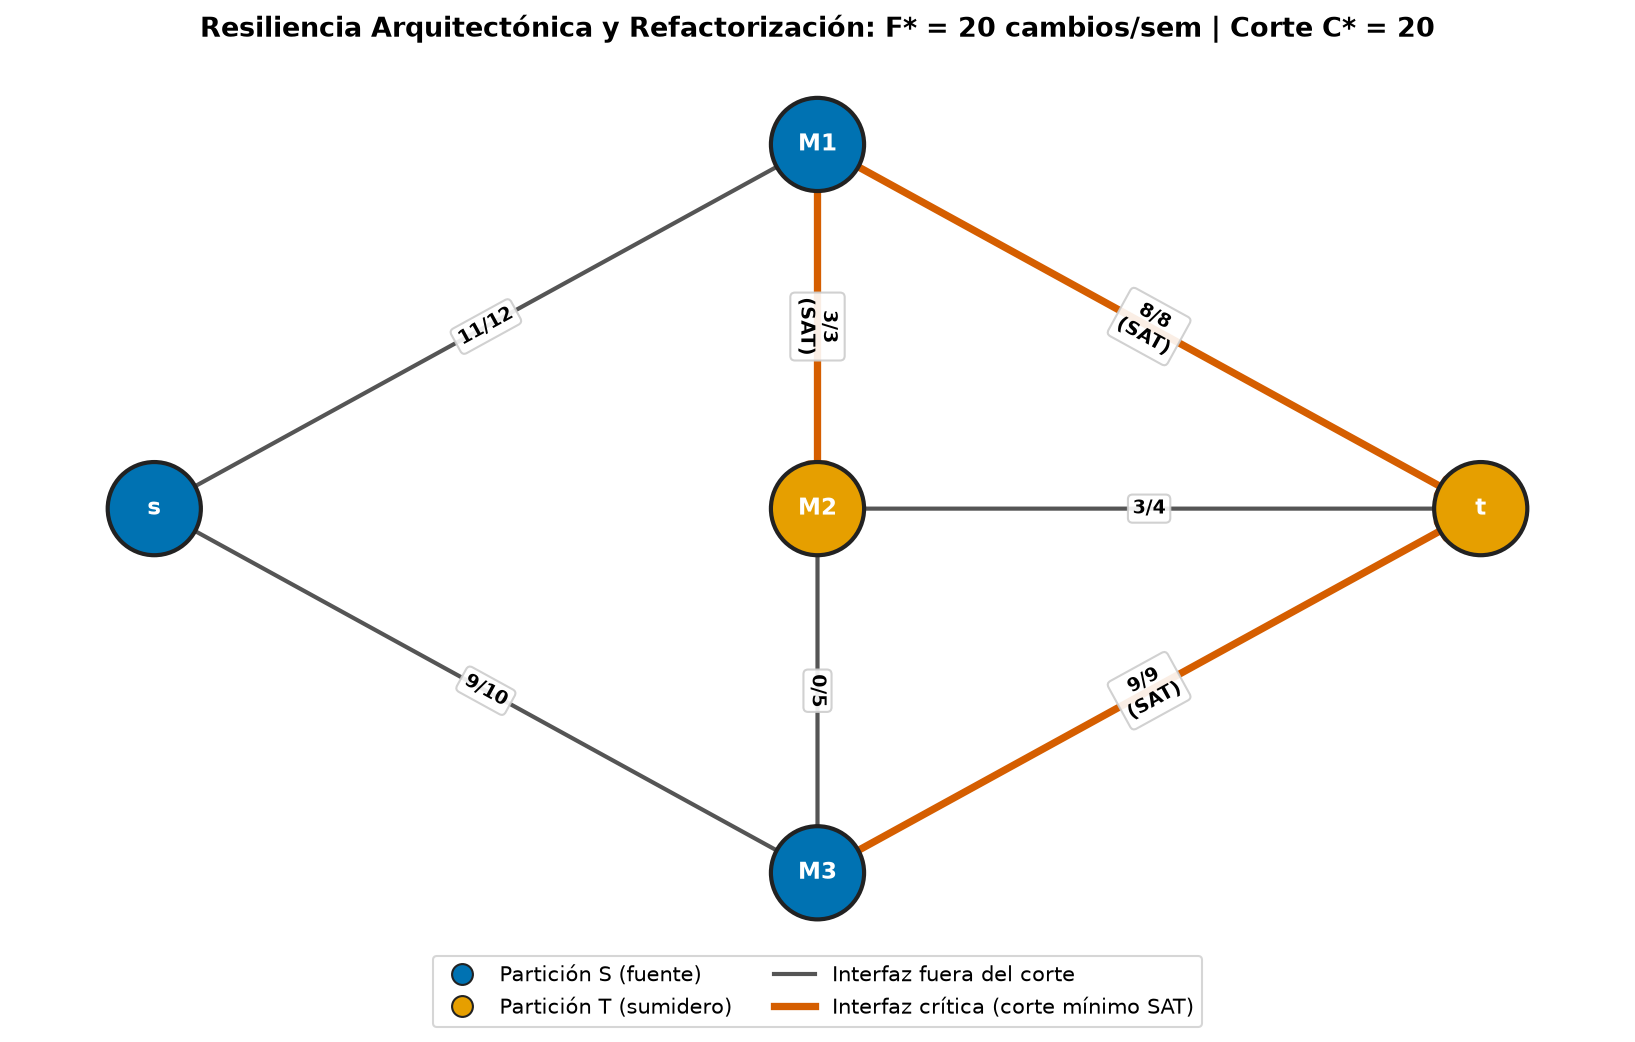

In [1]:
# ==============================================================================
# RESOLUCIÓN EN PYTHON: FLUJO MÁXIMO Y CORTE MÍNIMO EN SISTEMAS HEREDADOS
# Caso: Resiliencia ante Cambios y Refactorización Arquitectónica
# ==============================================================================

import matplotlib.pyplot as plt
# Crea símbolos explícitos para la leyenda de nodos y arcos del grafo.
from matplotlib.lines import Line2D
import networkx as nx
import pulp

# ------------------------------------------------------------------------------
# 1. FORMULACIÓN Y RESOLUCIÓN MEDIANTE PROGRAMACIÓN LINEAL (PuLP)
# ------------------------------------------------------------------------------

# Crear el problema de maximización
modelo = pulp.LpProblem("Flujo_Maximo_Deuda_Tecnica", pulp.LpMaximize)

# Definir la topología de la red y capacidades (cambios/semana)
capacidades = {
    ('s', 'M1'): 12,  # Gateway -> Matrícula
    ('s', 'M3'): 10,  # Gateway -> Finanzas
    ('M1', 'M2'): 3,  # Matrícula -> Académico
    ('M1', 't'): 8,  # Matrícula -> Base de Datos
    ('M2', 't'): 4,  # Académico -> Base de Datos
    ('M2', 'M3'): 5,  # Académico -> Finanzas
    ('M3', 't'): 9,  # Finanzas -> Base de Datos
}

arcos = list(capacidades.keys())

# Variables de decisión continuas (flujo en cada arco y flujo total)
f = {
    e: pulp.LpVariable(
        f"f_{e[0]}_{e[1]}",
        lowBound=0,
        upBound=capacidades[e],
        cat='Continuous',
    )
    for e in arcos
}
F = pulp.LpVariable("Flujo_Total_Cambios", lowBound=0, cat='Continuous')

# Función Objetivo: Maximizar el flujo total absorbido por la arquitectura
modelo += F, "Maximizar_Cambios_Semanales"

# Restricciones de Balance y Conservación de Flujo:
# Balance en la fuente (Gateway 's')
modelo += (f[('s', 'M1')] + f[('s', 'M3')] == F), "Balance_Nodo_s"

# Conservación en subsistemas intermedios (Entradas = Salidas)
modelo += (f[('s', 'M1')] - f[('M1', 'M2')] - f[('M1', 't')] == 0), (
    "Balance_Nodo_M1"
)
modelo += (f[('M1', 'M2')] - f[('M2', 'M3')] - f[('M2', 't')] == 0), (
    "Balance_Nodo_M2"
)
modelo += (f[('s', 'M3')] + f[('M2', 'M3')] - f[('M3', 't')] == 0), (
    "Balance_Nodo_M3"
)

# Balance en el sumidero (Base de Datos 't')
modelo += (f[('M1', 't')] + f[('M2', 't')] + f[('M3', 't')] == F), (
    "Balance_Nodo_t"
)

# Resolver con el solver CBC (Simplex continuo)
modelo.solve(pulp.PULP_CBC_CMD(msg=0))

# ------------------------------------------------------------------------------
# 2. VALIDACIÓN DEL CORTE MÍNIMO CON NETWORKX
# ------------------------------------------------------------------------------
G = nx.DiGraph()
for (u, v), cap in capacidades.items():
    G.add_edge(u, v, capacity=cap)

# Algoritmo combinatorio de corte mínimo
cut_val, partition = nx.minimum_cut(G, 's', 't')
set_S, set_T = partition

print('=' * 65)
print(f'ESTADO DE LA OPTIMIZACIÓN : {pulp.LpStatus[modelo.status]}')
print(
    f'FLUJO MÁXIMO ÓPTIMO (F*)  : {pulp.value(F):.1f} cambios concurrentes/semana'
)
print(f'CAPACIDAD CORTE MÍNIMO    : {cut_val:.1f}')
print('=' * 65)
print('ASIGNACIÓN DETALLADA DE FLUJO EN CADA INTERFAZ:')
for e in arcos:
    flujo = f[e].varValue
    cap = capacidades[e]
    saturado = ' [SATURADO - CUELLO DE BOTELLA]' if flujo == cap else ''
    print(f'  Interfaz {e[0]:>2} -> {e[1]:<2} : {flujo:4.1f} / {cap:2d}{saturado}')

print('\nPARTICIÓN ÓPTIMA DEL CORTE (DESACOPLAMIENTO ESTRATÉGICO):')
print(f'  Lado Fuente   (S) : {sorted(list(set_S))}')
print(f'  Lado Sumidero (T) : {sorted(list(set_T))}')

# Arcos que cruzan el corte de S a T
arcos_corte = [(u, v) for u in set_S for v in set_T if G.has_edge(u, v)]
print(f'  Interfaces críticas a refactorizar : {arcos_corte}')
print('=' * 65)

# ------------------------------------------------------------------------------
# 3. VISUALIZACIÓN GRÁFICA DEL MODELO
# ------------------------------------------------------------------------------
pos = {
    's': (0.0, 1.0),
    'M1': (1.0, 2.0),
    'M2': (1.0, 1.0),
    'M3': (1.0, 0.0),
    't': (2.0, 1.0),
}

plt.figure(figsize=(11, 7), dpi=150)
ax = plt.gca()

# Clasificar aristas normales vs aristas del corte
cut_edges = [(u, v) for u in set_S for v in set_T if G.has_edge(u, v)]
normal_edges = [e for e in G.edges() if e not in cut_edges]

# Dibujar aristas
nx.draw_networkx_edges(
    G,
    pos,
    edgelist=normal_edges,
    edge_color='#555555',
    width=2.0,
    arrowsize=20,
    connectionstyle='arc3,rad=0.0',
)
nx.draw_networkx_edges(
    G,
    pos,
    edgelist=cut_edges,
    edge_color='#D55E00',
    width=3.5,
    arrowsize=22,
    connectionstyle='arc3,rad=0.0',
)

# Dibujar nodos coloreados por partición
node_colors = ['#0072B2' if n in set_S else '#E69F00' for n in G.nodes()]
nx.draw_networkx_nodes(
    G,
    pos,
    node_color=node_colors,
    node_size=2000,
    edgecolors='#222222',
    linewidths=2.0,
)
nx.draw_networkx_labels(
    G, pos, font_size=11, font_weight='bold', font_color='white'
)

# Etiquetas de flujo/capacidad
edge_labels = {}
for u, v in G.edges():
    val = f[(u, v)].varValue
    cap = capacidades[(u, v)]
    sat = '\n(SAT)' if (u, v) in cut_edges else ''
    edge_labels[(u, v)] = f'{val:.0f}/{cap}{sat}'

nx.draw_networkx_edge_labels(
    G,
    pos,
    edge_labels=edge_labels,
    font_size=9,
    font_weight='bold',
    bbox=dict(
        boxstyle='round,pad=0.25',
        facecolor='white',
        edgecolor='#CCCCCC',
        alpha=0.9,
    ),
)

plt.title(
    f'Resiliencia Arquitectónica y Refactorización: F* = {pulp.value(F):.0f} cambios/sem | Corte C* = {cut_val}',
    fontsize=13,
    fontweight='bold',
    pad=15,
)
# Define la leyenda explícitamente: las flechas de NetworkX no se recogen automáticamente.
leyenda = [
    Line2D([], [], marker='o', linestyle='None', markersize=10,
           markerfacecolor='#0072B2', markeredgecolor='#222222', label='Partición S (fuente)'),
    Line2D([], [], marker='o', linestyle='None', markersize=10,
           markerfacecolor='#E69F00', markeredgecolor='#222222', label='Partición T (sumidero)'),
    Line2D([], [], color='#555555', linewidth=2.0, label='Interfaz fuera del corte'),
    Line2D([], [], color='#D55E00', linewidth=3.5, label='Interfaz crítica (corte mínimo SAT)'),
]
ax.legend(handles=leyenda, loc='lower center', bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=True)
plt.axis('off')
plt.tight_layout()
plt.show()